### Actividad regresión logística

Dr. Hugo García Tecocoatzi

### Instrucciones:
Vel el ejemplo y realiza la actividad final.

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, accuracy_score)

import statsmodels.api as sm
from scipy import stats

%matplotlib inline
sns.set_style('whitegrid')

In [2]:
# Dataset: Breast Cancer Wisconsin (clasificación binaria: maligno vs benigno)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='Diagnostico')  # 0 = maligno, 1 = benigno

df = pd.concat([X, y], axis=1)

print(f"Forma del dataset: {df.shape}")
print(f"Clases: {dict(y.value_counts())}")
print(f"Proporción de benignos: {y.mean():.3f}")
df.head()

Forma del dataset: (569, 31)
Clases: {1: np.int64(357), 0: np.int64(212)}
Proporción de benignos: 0.627


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Para simplificar el ejercicio, usamos 4 variables representativas
vars_modelo = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']

print("Estadísticas descriptivas por clase:\n")
print(df.groupby('Diagnostico')[vars_modelo].agg(['mean', 'std']).round(3))

Estadísticas descriptivas por clase:

            mean radius        mean texture        mean perimeter          \
                   mean    std         mean    std           mean     std   
Diagnostico                                                                 
0                17.463  3.204       21.605  3.779        115.365  21.855   
1                12.147  1.781       17.915  3.995         78.075  11.807   

            mean area           
                 mean      std  
Diagnostico                     
0             978.376  367.938  
1             462.790  134.287  


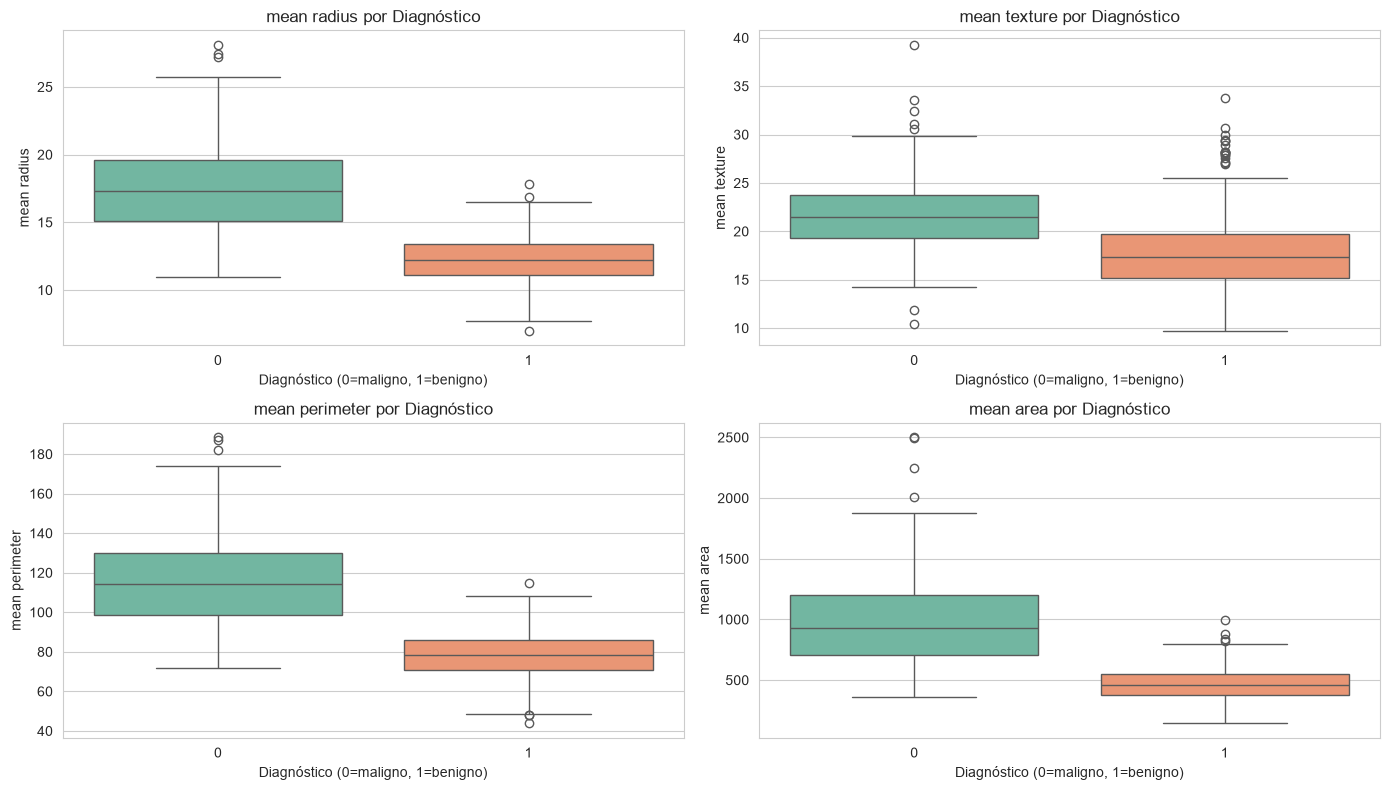

In [4]:
# Boxplots por diagnóstico
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(vars_modelo):
    sns.boxplot(x='Diagnostico', y=var, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{var} por Diagnóstico')
    axes[i].set_xlabel('Diagnóstico (0=maligno, 1=benigno)')

plt.tight_layout()
plt.show()

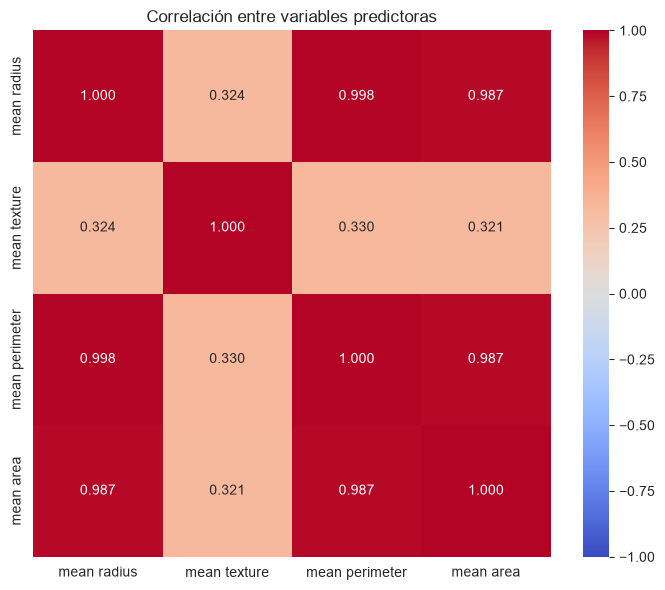

In [5]:
# Correlación entre variables
plt.figure(figsize=(7, 6))
sns.heatmap(df[vars_modelo].corr(), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlación entre variables predictoras')
plt.tight_layout()
plt.show()

In [6]:
# Ajustar regresión logística con statsmodels (da p-valores y OR)
X_sm = sm.add_constant(df[vars_modelo])
y_sm = df['Diagnostico']

modelo_logit = sm.Logit(y_sm, X_sm).fit(disp=False)
print(modelo_logit.summary())

                           Logit Regression Results                           
Dep. Variable:            Diagnostico   No. Observations:                  569
Model:                          Logit   Df Residuals:                      564
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7187
Time:                        23:18:00   Log-Likelihood:                -105.68
converged:                       True   LL-Null:                       -375.72
Covariance Type:            nonrobust   LLR p-value:                1.437e-115
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -1.7729      6.870     -0.258      0.796     -15.238      11.692
mean radius        9.4287      1.640      5.751      0.000       6.215      12.642
mean texture      -0.2376      0.046

In [7]:
# Odds Ratios con intervalos de confianza al 95%
odds_ratios = pd.DataFrame({
    'Coeficiente': modelo_logit.params,
    'OR': np.exp(modelo_logit.params),
    'IC 2.5%': np.exp(modelo_logit.conf_int()[0]),
    'IC 97.5%': np.exp(modelo_logit.conf_int()[1]),
    'p-valor': modelo_logit.pvalues
}).round(4)

print("=== ODDS RATIOS ===\n")
print(odds_ratios)

=== ODDS RATIOS ===

                Coeficiente          OR   IC 2.5%     IC 97.5%  p-valor
const               -1.7729      0.1698    0.0000  119645.3293   0.7964
mean radius          9.4287  12440.8159  500.2941  309365.8457   0.0000
mean texture        -0.2376      0.7885    0.7205       0.8630   0.0000
mean perimeter      -1.1507      0.3164    0.2293       0.4367   0.0000
mean area           -0.0328      0.9678    0.9456       0.9905   0.0056


In [8]:
# Predicciones de probabilidad
y_pred_prob = modelo_logit.predict(X_sm)
y_pred = (y_pred_prob > 0.5).astype(int)

# Matriz de confusión
print("Matriz de confusión:\n")
print(confusion_matrix(y_sm, y_pred))

print("\nReporte de clasificación:\n")
print(classification_report(y_sm, y_pred, target_names=['maligno', 'benigno']))

print(f"Accuracy: {accuracy_score(y_sm, y_pred):.4f}")

Matriz de confusión:

[[183  29]
 [ 17 340]]

Reporte de clasificación:

              precision    recall  f1-score   support

     maligno       0.92      0.86      0.89       212
     benigno       0.92      0.95      0.94       357

    accuracy                           0.92       569
   macro avg       0.92      0.91      0.91       569
weighted avg       0.92      0.92      0.92       569

Accuracy: 0.9192


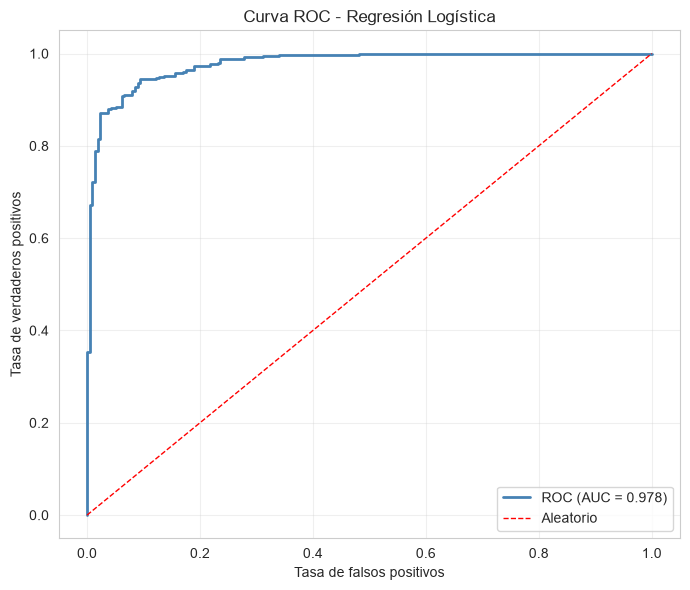

In [9]:
# Curva ROC
fpr, tpr, _ = roc_curve(y_sm, y_pred_prob)
auc = roc_auc_score(y_sm, y_pred_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', lw=1, label='Aleatorio')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Regresión Logística')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Implementación de la prueba de Hosmer-Lemeshow
def hosmer_lemeshow(y_true, y_prob, g=10):
    """
    Prueba de bondad de ajuste de Hosmer-Lemeshow.
    y_true: valores observados (0/1)
    y_prob: probabilidades predichas
    g: número de grupos (por defecto 10)
    """
    # Crear DataFrame auxiliar
    df_hl = pd.DataFrame({'y': y_true, 'p': y_prob})
    df_hl['grupo'] = pd.qcut(df_hl['p'], q=g, duplicates='drop')
    
    # Calcular observados y esperados por grupo
    hl_tabla = df_hl.groupby('grupo').agg(
        n=('y', 'size'),
        observados=('y', 'sum'),
        esperados=('p', 'sum'),
        p_medio=('p', 'mean')
    )
    hl_tabla['obs_no'] = hl_tabla['n'] - hl_tabla['observados']
    hl_tabla['esp_no'] = hl_tabla['n'] - hl_tabla['esperados']
    
    # Estadístico HL
    HL = ((hl_tabla['observados'] - hl_tabla['esperados'])**2 /
          (hl_tabla['esperados'] * (1 - hl_tabla['p_medio']))).sum() \
       + ((hl_tabla['obs_no'] - hl_tabla['esp_no'])**2 /
          (hl_tabla['esp_no'] * (1 - hl_tabla['p_medio']))).sum()
    
    gl = len(hl_tabla) - 2
    p_valor = 1 - stats.chi2.cdf(HL, gl)
    
    return HL, gl, p_valor, hl_tabla

HL, gl, p_valor, tabla = hosmer_lemeshow(y_sm, y_pred_prob, g=10)

print(f"Estadístico HL: {HL:.4f}")
print(f"Grados de libertad: {gl}")
print(f"p-valor: {p_valor:.4f}\n")

if p_valor > 0.05:
    print("✅ No se rechaza H0: el modelo tiene buen ajuste")
else:
    print("⚠️ Se rechaza H0: posible falta de ajuste")

print("\nTabla por grupos:")
print(tabla.round(3))

Estadístico HL: 207.9429
Grados de libertad: 8
p-valor: 0.0000

⚠️ Se rechaza H0: posible falta de ajuste

Tabla por grupos:
                      n  observados  esperados  p_medio  obs_no  esp_no
grupo                                                                  
(-0.001, 3.74e-05]   57           0      0.000    0.000      57  57.000
(3.74e-05, 0.00606]  57           1      0.085    0.001      56  56.915
(0.00606, 0.25]      57           7      4.388    0.077      50  52.612
(0.25, 0.703]        57          24     28.073    0.493      33  28.927
(0.703, 0.904]       57          44     47.261    0.829      13   9.739
(0.904, 0.957]       56          54     52.441    0.936       2   3.559
(0.957, 0.979]       57          57     55.283    0.970       0   1.717
(0.979, 0.989]       57          56     56.132    0.985       1   0.868
(0.989, 0.994]       57          57     56.515    0.991       0   0.485
(0.994, 0.999]       57          57     56.821    0.997       0   0.179


In [11]:
# Pseudo R²
ll_modelo = modelo_logit.llf        # log-verosimilitud del modelo completo
ll_nulo = modelo_logit.llnull       # log-verosimilitud del modelo nulo
n = len(y_sm)

# McFadden
r2_mcfadden = 1 - (ll_modelo / ll_nulo)

# Cox-Snell
r2_coxsnell = 1 - np.exp((2 / n) * (ll_nulo - ll_modelo))

# Nagelkerke (ajusta Cox-Snell para que el máximo sea 1)
r2_nagelkerke = r2_coxsnell / (1 - np.exp((2 / n) * ll_nulo))

print("=== PSEUDO R² ===\n")
print(f"Log-verosimilitud modelo completo: {ll_modelo:.4f}")
print(f"Log-verosimilitud modelo nulo:     {ll_nulo:.4f}\n")
print(f"McFadden:    {r2_mcfadden:.4f}")
print(f"Cox-Snell:   {r2_coxsnell:.4f}")
print(f"Nagelkerke:  {r2_nagelkerke:.4f}")

=== PSEUDO R² ===

Log-verosimilitud modelo completo: -105.6834
Log-verosimilitud modelo nulo:     -375.7200

McFadden:    0.7187
Cox-Snell:   0.6129
Nagelkerke:  0.8362


In [12]:
# Comparación con sklearn
X_train, X_test, y_train, y_test = train_test_split(
    df[vars_modelo], df['Diagnostico'], test_size=0.3,
    random_state=42, stratify=df['Diagnostico']
)

# HL_w, gl_w, p_w, _ = hosmer_lemeshow(y_w_sm, y_prob_

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

modelo_sk = LogisticRegression(max_iter=1000)
modelo_sk.fit(X_train_sc, y_train)

y_pred_sk = modelo_sk.predict(X_test_sc)
y_prob_sk = modelo_sk.predict_proba(X_test_sc)[:, 1]

print("Accuracy en test: {:.4f}".format(accuracy_score(y_test, y_pred_sk)))
print("AUC en test:      {:.4f}".format(roc_auc_score(y_test, y_prob_sk)))
print("\nReporte de clasificación (test):\n")
print(classification_report(y_test, y_pred_sk, target_names=['maligno', 'benigno']))

Accuracy en test: 0.8889
AUC en test:      0.9647

Reporte de clasificación (test):

              precision    recall  f1-score   support

     maligno       0.87      0.83      0.85        64
     benigno       0.90      0.93      0.91       107

    accuracy                           0.89       171
   macro avg       0.88      0.88      0.88       171
weighted avg       0.89      0.89      0.89       171



In [13]:
# ACTIVIDAD: Replicar todo el análisis con el dataset de Vinos
# El dataset de vinos tiene 3 clases. Para hacer regresión logística binaria,
# debemos convertir el problema a dos clases. Por ejemplo:
#   - clase 0 (vino tinto A) vs. clases 1 y 2 (resto)
# O bien usar solo dos clases filtrando una.

print("ACTIVIDAD: Regresión Logística con el dataset de Vinos\n")
print("Instrucciones:")
print("1. Cargar el dataset con load_wine()")
print("2. Convertir el problema a binario (por ejemplo, clase 0 vs. resto)")
print("3. Seleccionar 3 o 4 variables predictoras")
print("4. Explorar los datos: estadísticas, boxplots, correlación")
print("5. Ajustar el modelo con statsmodels")
print("6. Interpretar los Odds Ratios")
print("7. Evaluar con matriz de confusión, ROC, Hosmer-Lemeshow y pseudo R²")
print("8. Comparar con sklearn")


ACTIVIDAD: Regresión Logística con el dataset de Vinos

Instrucciones:
1. Cargar el dataset con load_wine()
2. Convertir el problema a binario (por ejemplo, clase 0 vs. resto)
3. Seleccionar 3 o 4 variables predictoras
4. Explorar los datos: estadísticas, boxplots, correlación
5. Ajustar el modelo con statsmodels
6. Interpretar los Odds Ratios
7. Evaluar con matriz de confusión, ROC, Hosmer-Lemeshow y pseudo R²
8. Comparar con sklearn


Estadísticas descriptivas por clase:

      alcohol        malic_acid           ash        total_phenols       
         mean    std       mean    std   mean    std          mean    std
Clase                                                                    
0      13.745  0.462      2.011  0.689  2.456  0.227         2.840  0.339
1      12.279  0.538      1.933  1.016  2.245  0.315         2.259  0.545
2      13.154  0.530      3.334  1.088  2.437  0.185         1.679  0.357


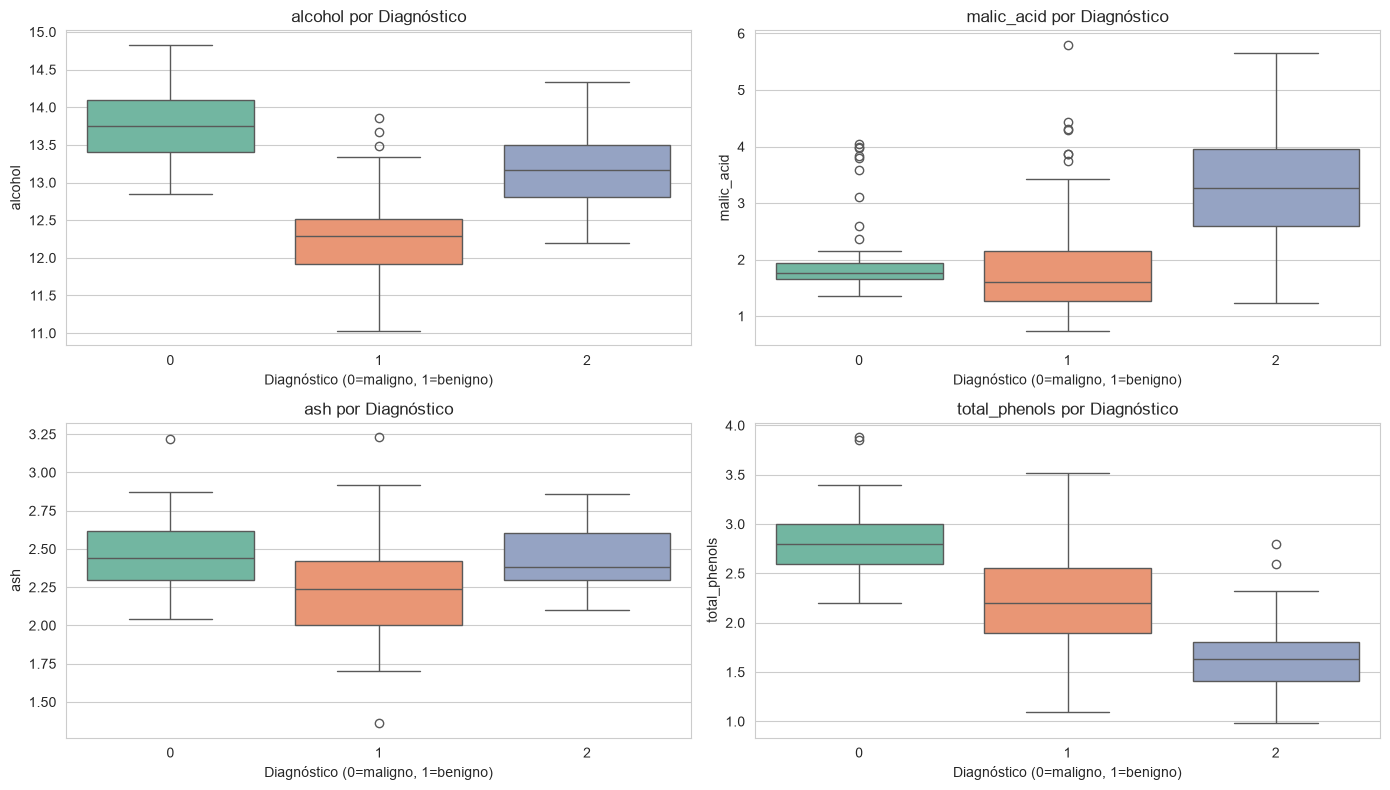

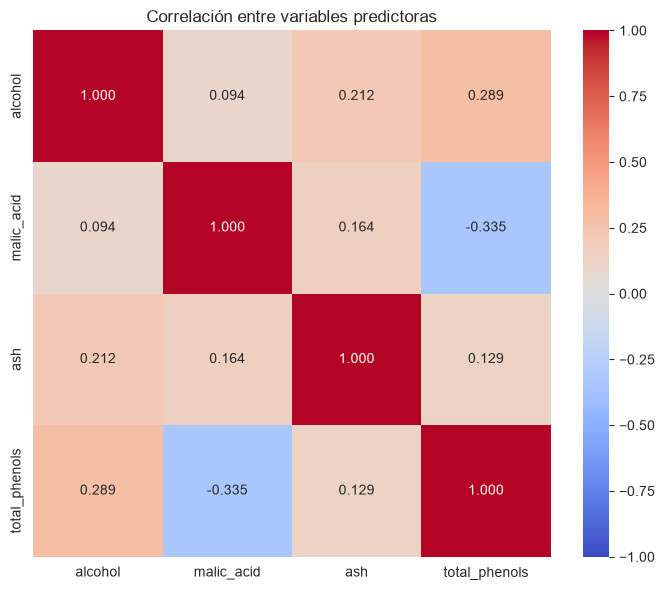

McFadden R²: 0.6601


In [27]:
# ============================================================
# PLANTILLA PARA LA ACTIVIDAD CON EL DATASET DE VINOS
# Completa cada sección
# ============================================================

# 1. Cargar datos
wine = load_wine()
X_w = pd.DataFrame(wine.data, columns=wine.feature_names)
y_w = pd.Series(wine.target, name='Clase')
df_w = pd.concat([X_w, y_w], axis=1)


# 2. Convertir a binario
df_w['Clase_bin'] = (df_w['Clase'] == 0).astype(int)


# 3. Seleccionar variables (elige 3 o 4)
vars_w = ['alcohol', 'malic_acid', 'ash', 'total_phenols']

# 4. Visualización
# Para simplificar el ejercicio, usamos 4 variables representativas
vars_modelo = ['mean alcohol', 'mean acid', 'mean ash', 'mean phenols']

print("Estadísticas descriptivas por clase:\n")
print(df_w.groupby('Clase')[vars_w].agg(['mean', 'std']).round(3))
# Boxplots por diagnóstico
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(vars_w):
    sns.boxplot(x='Clase', y=var, data=df_w, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{var} por Diagnóstico')
    axes[i].set_xlabel('Diagnóstico (0=maligno, 1=benigno)')

plt.tight_layout()
plt.show()
# Correlación entre variables
plt.figure(figsize=(7, 6))
sns.heatmap(df_w[vars_w].corr(), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlación entre variables predictoras')
plt.tight_layout()
plt.show()

# 5. Ajustar modelo con statsmodels
X_w_sm = sm.add_constant(df_w[vars_w])
y_w_sm = df_w['Clase_bin']
modelo_w = sm.Logit(y_w_sm, X_w_sm).fit(disp=False)


# 6. Odds Ratios
or_w = pd.DataFrame({
     'Coef': modelo_w.params,
     'OR': np.exp(modelo_w.params),
     'IC 2.5%': np.exp(modelo_w.conf_int()[0]),
     'IC 97.5%': np.exp(modelo_w.conf_int()[1]),
     'p': modelo_w.pvalues
 }).round(4)

# 7. Evaluación
y_prob_w = modelo_w.predict(X_w_sm)
y_pred_w = (y_prob_w > 0.5).astype(int)


HL_w, gl_w, p_w, _ = hosmer_lemeshow(y_w_sm, y_prob_w, g=10)

ll_mod_w = modelo_w.llf
ll_nul_w = modelo_w.llnull
n_w = len(y_w_sm)
r2_mcf_w = 1 - (ll_mod_w / ll_nul_w)
print(f"McFadden R²: {r2_mcf_w:.4f}")

# 8. Comparar con sklearn

In [19]:
or_w

,Coef,OR,IC 2.5%,IC 97.5%,p
const,-50.8074,0.0000,0.0000,0.0000,0.0000
alcohol,3.0418,20.9433,6.6317,66.1403,0.0000
malic_acid,-0.2068,0.8132,0.4539,1.4568,0.4869
ash,0.9753,2.6518,0.3494,20.1258,0.3456
total_phenols,3.3311,27.9680,6.6002,118.5133,0.0000


Este modelo de regresión logística muestra que únicamente el alcohol y los fenoles totales tienen un impacto estadísticamente significativo, aumentando de forma muy marcada las probabilidades del evento positivo (multiplicándolas por 20.94 y 27.97, respectivamente). Por el contrario, el ácido málico y la ceniza no presentan un efecto relevante ni estadísticamente demostrable en este análisis

In [16]:
# Comparación con sklearn
X_train, X_test, y_train, y_test = train_test_split(
    df_w[vars_w], df_w['Clase_bin'], test_size=0.3,
    random_state=42, stratify=df_w['Clase_bin']
)

# HL_w, gl_w, p_w, _ = hosmer_lemeshow(y_w_sm, y_prob_

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

modelo_sk = LogisticRegression(max_iter=1000)
modelo_sk.fit(X_train_sc, y_train)

y_pred_sk = modelo_sk.predict(X_test_sc)
y_prob_sk = modelo_sk.predict_proba(X_test_sc)[:, 1]

print("Accuracy en test: {:.4f}".format(accuracy_score(y_test, y_pred_sk)))
print("AUC en test:      {:.4f}".format(roc_auc_score(y_test, y_prob_sk)))
print("\nReporte de clasificación (test):\n")
print(classification_report(y_test, y_pred_sk, target_names=['0', '1']))

Accuracy en test: 0.8333
AUC en test:      0.9259

Reporte de clasificación (test):

              precision    recall  f1-score   support

           0       0.86      0.89      0.88        36
           1       0.76      0.72      0.74        18

    accuracy                           0.83        54
   macro avg       0.81      0.81      0.81        54
weighted avg       0.83      0.83      0.83        54

